# Model comparison: Decision Tree and Random Forest vs baseline

Same setup as `03_baseline_model.ipynb`: Dataset A, test month 2026-04, and the training window X picked on a rolling backtest over 2025-10 to 2026-03. The test month is scored once per model.

Trees split on thresholds, so they don't need scaling, and logging a feature changes nothing for them. The one experiment that still matters is the **log target**, because it changes what the squared-error splits are trying to minimize.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from idx_exchange_data_science import dataset_a as da
from idx_exchange_data_science.modeling import (
    backtest, best_windows, build_model, fit_and_score, fitted_pipeline, score_on_test,
)
from idx_exchange_data_science.splits import validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

TEST_MONTH = "2026-04"
WINDOWS = [1, 2, 3, 6, 9, 12, 18]
EVAL_MONTHS = validation_months(TEST_MONTH, n_months=6)
RESULTS_DIR = Path("../results")

df = da.load_clean("../data/processed/CRMLSSoldDatasetA.csv")
baseline = pd.read_csv(RESULTS_DIR / "baseline_results.csv").query("baseline")
baseline

,model,X,n_train,n_test,train_r2,test_r2,test_mae,test_mape,validation_r2,baseline
3,LR + log target + log features,18,189534,12309,0.8162,0.8102,"216,765.9942",0.1586,0.8007,True


## 1. Models
- **Decision Tree:** `min_samples_leaf=20`. An unrestricted tree memorizes the training set (see section 4), so it needs some limit.
- **Random Forest:** 200 trees, `min_samples_leaf=2`, each split looks at a third of the features. These are common defaults for regression forests and weren't tuned.

In [2]:
def decision_tree():
    return DecisionTreeRegressor(min_samples_leaf=20, random_state=0)


def random_forest():
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=1 / 3, n_jobs=-1, random_state=0)


models = {
    "Decision Tree": build_model(decision_tree()),
    "Decision Tree + log target": build_model(decision_tree(), log_target=True),
    "Random Forest": build_model(random_forest()),
    "Random Forest + log target": build_model(random_forest(), log_target=True),
}

## 2. Choosing the training window X

In [3]:
results = backtest(models, df, EVAL_MONTHS, WINDOWS)
mean_r2 = results.pivot_table(index="X", columns="model", values="r2", aggfunc="mean")[list(models)]
mean_r2

model,Decision Tree,Decision Tree + log target,Random Forest,Random Forest + log target
X,,,,
1,0.7696,0.7634,0.8287,0.8172
2,0.7925,0.7962,0.8475,0.8391
3,0.8044,0.8077,0.8577,0.8495
6,0.8239,0.8277,0.8722,0.8660
9,0.8357,0.8372,0.8793,0.8753
12,0.8394,0.8396,0.8831,0.8788
18,0.8508,0.8509,0.8895,0.8849


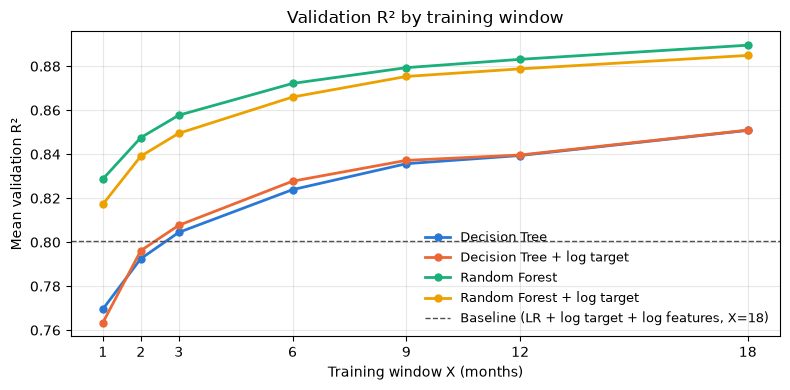

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for color, name in zip(COLORS, models):
    ax.plot(mean_r2.index, mean_r2[name], marker="o", markersize=5, linewidth=2, color=color, label=name)
ax.axhline(baseline["validation_r2"].item(), color="#52514e", linewidth=1, linestyle="--",
           label=f"Baseline ({baseline['model'].item()}, X={baseline['X'].item()})")
ax.set(xlabel="Training window X (months)", ylabel="Mean validation R²", title="Validation R² by training window",
       xticks=WINDOWS)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

In [5]:
best_x = best_windows(results)
best_x

{'Decision Tree': 18,
 'Decision Tree + log target': 18,
 'Random Forest': 18,
 'Random Forest + log target': 18}

**Observations**
- **More history helps the trees too.** All four models score best at X = 18, the longest window tried. The forest gains 0.06 R² going from 1 to 18 months, more than linear regression did. Trees need more rows before they can split finely within each area.
- **Even with a single month of training data, the forest beats the baseline** (0.829 vs 0.801).
- **The log target barely matters for trees.** For the forest it costs about 0.005 R². For a single tree it makes no difference at long windows.

## 3. Test month

In [6]:
validation_r2 = {name: mean_r2.loc[x, name] for name, x in best_x.items()}
test_results, fitted = score_on_test(models, df, TEST_MONTH, best_x)
test_results["validation_r2"] = test_results["model"].map(validation_r2)

comparison = (
    pd.concat([baseline.drop(columns="baseline"), test_results], ignore_index=True)
    .assign(r2_vs_baseline=lambda t: t["test_r2"] - baseline["test_r2"].item())
    .sort_values("test_r2", ascending=False, ignore_index=True)
)
comparison

,model,X,n_train,n_test,train_r2,test_r2,test_mae,test_mape,validation_r2,r2_vs_baseline
0,Random Forest,18,189534,12309,0.9560,0.8914,"159,625.9106",0.1189,0.8895,0.0812
1,Random Forest + log target,18,189534,12309,0.9497,0.8858,"160,595.4159",0.1151,0.8849,0.0757
2,Decision Tree,18,189534,12309,0.8883,0.8557,"190,960.2756",0.1427,0.8508,0.0456
3,Decision Tree + log target,18,189534,12309,0.8875,0.8504,"191,266.1218",0.1398,0.8509,0.0403
4,LR + log target + log features,18,189534,12309,0.8162,0.8102,"216,765.9942",0.1586,0.8007,0.0000


**Observations**
- **Random Forest is the best model: test R² 0.891, +0.081 over the baseline.** MAE drops from \$217K to \$160K and MAPE from 15.9% to 11.9%.
- **The single Decision Tree lands in between** (0.856).
- **Test R² tracks validation R² within 0.006 for every model,** so the backtest is a reliable guide for choosing models.
- **The log target trades R² for MAPE.** For both tree models it gives slightly lower R² but slightly lower MAPE: it pays more attention to relative error on cheaper homes and less to absolute dollars on expensive ones.

## 4. Model behavior
### Overfitting: tree size vs. validation score
A single tree's main setting is how small its leaves can get. Here it's fit on the 18 months before 2026-03 and scored on 2026-03, with the log target.

,min_samples_leaf,train_r2,validation_r2
0,1,0.9561,0.7922
1,2,0.9469,0.8078
2,5,0.9244,0.8460
3,10,0.9053,0.8472
4,20,0.8874,0.8520
5,50,0.8661,0.8510
6,100,0.8520,0.8400
7,200,0.8383,0.8265


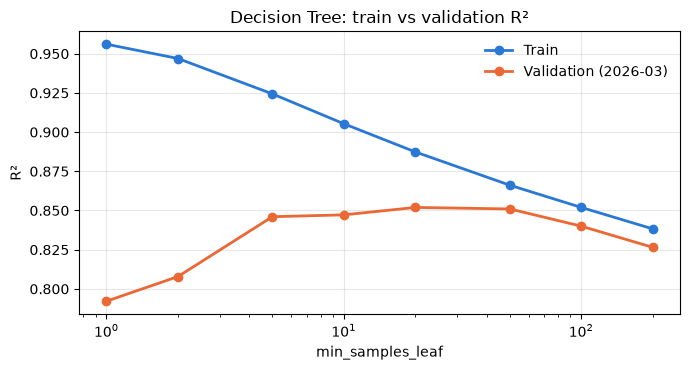

In [7]:
val_month = EVAL_MONTHS[-1]
train_val, val = da.split(df, val_month, 18)
leaf_sizes = [1, 2, 5, 10, 20, 50, 100, 200]
curve = []
for leaf in leaf_sizes:
    tree = build_model(DecisionTreeRegressor(min_samples_leaf=leaf, random_state=0), log_target=True)
    _, train_scores, val_scores = fit_and_score(tree, train_val, val)
    curve.append({"min_samples_leaf": leaf, "train_r2": train_scores["r2"], "validation_r2": val_scores["r2"]})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curve["min_samples_leaf"], curve["train_r2"], marker="o", linewidth=2, color=COLORS[0], label="Train")
ax.plot(curve["min_samples_leaf"], curve["validation_r2"], marker="o", linewidth=2, color=COLORS[1], label="Validation (2026-03)")
ax.set(xscale="log", xlabel="min_samples_leaf", ylabel="R²", title="Decision Tree: train vs validation R²")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
curve

**Observations**
- **With leaves of 1–2 rows the tree memorizes the training data.** Train R² is 0.95 but validation R² is about 0.80, no better than linear regression.
- **Validation peaks around 20 rows per leaf and falls again with very large leaves.** That supports the `min_samples_leaf=20` used above.
- **The forest gets a similar train/test gap (0.956 vs 0.891) without the cost.** It averages 200 deep trees, each built on a bootstrap sample with random feature subsets, so the errors of individual trees mostly cancel out.

### Feature importance
Impurity-based importances from the fitted trees, next to the absolute standardized coefficients of the baseline (refit here). Impurity importance favors features with many distinct values, so read it as a rough ranking only.

In [8]:
assert baseline["model"].item() == "LR + log target + log features"
baseline_model = build_model(LinearRegression(), scale=True, log_target=True, log_features=True)
train_base, test_base = da.split(df, TEST_MONTH, int(baseline["X"].item()))
baseline_model, _, _ = fit_and_score(baseline_model, train_base, test_base)

best_tree = max([n for n in models if n.startswith("Decision")], key=validation_r2.get)
best_forest = max([n for n in models if n.startswith("Random")], key=validation_r2.get)
coef = fitted_pipeline(baseline_model)[-1]
importance = pd.DataFrame({
    best_tree: fitted_pipeline(fitted[best_tree])[-1].feature_importances_,
    best_forest: fitted_pipeline(fitted[best_forest])[-1].feature_importances_,
    "Baseline |coefficient|": np.abs(pd.Series(coef.coef_, index=coef.feature_names_in_)),
}, index=fitted_pipeline(fitted[best_forest])[0].get_feature_names_out())
importance.sort_values(best_forest, ascending=False).head(12)

,Decision Tree + log target,Random Forest,Baseline |coefficient|
PostalCode_te,0.7813,0.3192,0.3277
City_te,0.0151,0.2203,0.0902
LivingArea,0.1530,0.1728,0.1712
BathroomsTotalInteger,0.0019,0.0994,0.0760
CountyOrParish_te,0.0087,0.0439,0.0435
Longitude,0.0117,0.0272,0.1007
LotSizeSquareFeet,0.0092,0.0267,0.0292
Latitude,0.0074,0.0229,0.0893
PropertyAge,0.0052,0.0200,0.0389
BedroomsTotal,0.0022,0.0191,0.0049


**Observations**
- **The single tree relies almost entirely on the ZIP encoding** (78% of importance), then living area. Everything else is close to unused. A single greedy tree commits to the strongest feature early.
- **The forest spreads importance more widely.** Restricting each split to a third of the features forces it to use the city encoding, bathrooms, coordinates, and lot size too. That's part of why it generalizes better.
- **All three models agree on what matters most:** location first, then living area.

### Error by price
Median absolute percentage error by price decile on the test month. Each model uses its own chosen window. The decile bands come from the baseline's test rows.

,Baseline (LR + log target + log features),Decision Tree + log target,Random Forest
ClosePrice,,,
"(0.0, 449897.6]",12.1000,9.7000,8.7000
"(449897.6, 575000.0]",10.6000,7.5000,5.7000
"(575000.0, 690000.0]",10.9000,7.6000,5.8000
"(690000.0, 800000.0]",10.6000,7.3000,5.8000
"(800000.0, 915000.0]",10.3000,7.6000,6.3000
"(915000.0, 1100000.0]",10.5000,9.4000,7.2000
"(1100000.0, 1325000.0]",11.2000,9.9000,8.5000
"(1325000.0, 1666566.6]",12.4000,11.0000,8.7000
"(1666566.6, 2350000.0]",14.2000,13.6000,10.6000


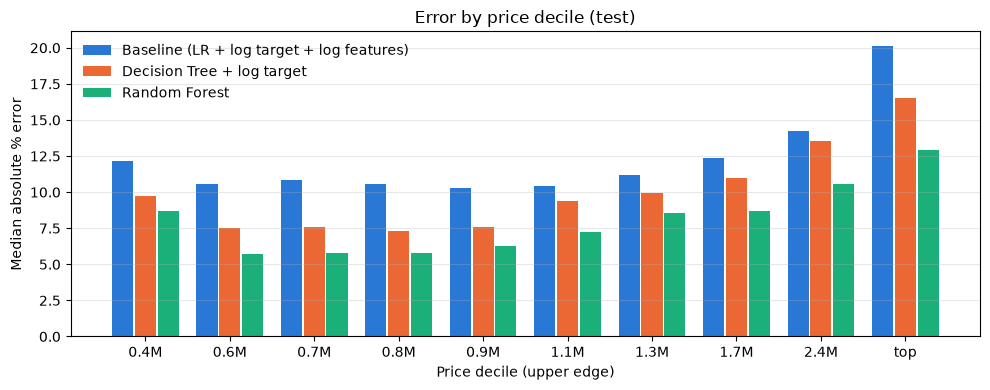

In [9]:
compared = {f"Baseline ({baseline['model'].item()})": (baseline_model, test_base),
            best_tree: (fitted[best_tree], da.split(df, TEST_MONTH, best_x[best_tree])[1]),
            best_forest: (fitted[best_forest], da.split(df, TEST_MONTH, best_x[best_forest])[1])}
bands = pd.qcut(test_base[da.TARGET], 10, retbins=True)[1]
bands[0], bands[-1] = 0, np.inf

errors = {}
for name, (model, test) in compared.items():
    pct_error = np.abs(model.predict(test[da.FEATURES]) - test[da.TARGET]) / test[da.TARGET]
    errors[name] = pct_error.groupby(pd.cut(test[da.TARGET], bands), observed=True).median() * 100
errors = pd.DataFrame(errors)

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.27
for i, (color, name) in enumerate(zip(COLORS, errors)):
    ax.bar(np.arange(10) + (i - 1) * width, errors[name], width=width - 0.02, color=color, label=name)
ax.set(xticks=range(10), xticklabels=[f"{b / 1e6:.1f}M" for b in bands[1:-1]] + ["top"],
       xlabel="Price decile (upper edge)", ylabel="Median absolute % error", title="Error by price decile (test)")
ax.grid(alpha=0.3, axis="y")
ax.legend(frameon=False)
plt.tight_layout()
errors.round(1)

**Observations**
- **The forest has the lowest error in every price decile.** Through the middle of the market it is about 6%, about half the baseline's error.
- **Every model is worst on the most expensive homes.** For the top decile the error is 20% for the baseline, 16.5% for the tree and 12.9% for the forest. Luxury homes are rare and depend on features Dataset A doesn't have, such as views, finishes and exact location.
- **The cheapest decile is the second-hardest for the trees.** It's a mix of small homes, rural properties and distressed sales.

### Training time
One fit on each model's chosen window:

In [10]:
fit_seconds = {}
for name, model in [("Baseline", baseline_model), *[(n, models[n]) for n in (best_tree, best_forest)]]:
    x = int(baseline["X"].item()) if name == "Baseline" else best_x[name]
    train, test = da.split(df, TEST_MONTH, x)
    start = time.perf_counter()
    fit_and_score(model, train, test)
    fit_seconds[name] = round(time.perf_counter() - start, 1)
fit_seconds

{'Baseline': 0.4, 'Decision Tree + log target': 1.3, 'Random Forest': 11.8}

## Strengths and weaknesses

| | Linear Regression (baseline) | Decision Tree | Random Forest |
|---|---|---|---|
| **Test R²** | 0.810 | 0.856 | **0.891** |
| **Strengths** | Fastest (under 1 s). Coefficients are directly interpretable. Stable from month to month. | Captures interactions (e.g. size is worth more in expensive ZIPs) without feature engineering. No scaling or log features needed. Easy to visualize. | Most accurate in every price band. Robust to outliers and skewed features. Little tuning needed, and more data keeps helping. |
| **Weaknesses** | A single linear surface can't bend for the luxury market, so predictions are pulled to the middle. Needs log transforms to be usable, and is unstable without them. | Overfits badly unless leaf size is limited. Predictions are a step function (one value per leaf). Leans on a single feature. | About 30× slower to train than the baseline and much larger in memory. Harder to explain than a single tree or coefficients. Can't predict above the highest prices in its training data. |

**Next steps worth trying:** gradient boosting (e.g. `HistGradientBoostingRegressor`), tuning the forest's `max_features` and leaf size on the backtest, and features for the luxury segment.

## 5. Record results

In [11]:
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
results.to_csv(RESULTS_DIR / "model_comparison_backtest.csv", index=False)
comparison[["model", "X", "validation_r2", "test_r2", "test_mae", "test_mape"]]

,model,X,validation_r2,test_r2,test_mae,test_mape
0,Random Forest,18,0.8895,0.8914,"159,625.9106",0.1189
1,Random Forest + log target,18,0.8849,0.8858,"160,595.4159",0.1151
2,Decision Tree,18,0.8508,0.8557,"190,960.2756",0.1427
3,Decision Tree + log target,18,0.8509,0.8504,"191,266.1218",0.1398
4,LR + log target + log features,18,0.8007,0.8102,"216,765.9942",0.1586
